In [ ]:
#setup
!pip install arch -q
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import xlogy
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from arch import arch_model
from google.colab import drive

drive.mount("/content/drive")
CSV_PATH = "/content/drive/MyDrive/FX_Clean.csv"

CURRENCIES = ["USAL", "USEU", "USJP", "USSZ", "USUK"]
# every pair in the file is quoted as USD per 1 unit of the foreign currency
PAIR_NAMES = {"USAL": "AUD/USD", "USEU": "EUR/USD", "USJP": "JPY/USD",
              "USSZ": "CHF/USD", "USUK": "GBP/USD"}

df = pd.read_csv(CSV_PATH, parse_dates=["observation_date"])
df = df.sort_values("observation_date").set_index("observation_date")

assert df.index.is_monotonic_increasing and df.index.is_unique
assert all(f"LogRet_{c}" in df.columns for c in CURRENCIES)


def get_returns(c):
    """Daily log returns (in %) for one pair, first NaN row dropped."""
    return df[f"LogRet_{c}"].dropna()


print(df.shape, "|", df.index.min().date(), "to", df.index.max().date())
df.head()

MessageError: Error: credential propagation was unsuccessful

In [ ]:
#built Shared loop
def walk_forward(returns, models, min_train=250, step=1):
    """For each day t, give every model ONLY the returns before t and store its
    variance forecast for day t next to what actually happened on day t."""
    returns = returns.dropna()
    if not returns.index.is_monotonic_increasing:
        raise ValueError("returns must be sorted by date")
    if len(returns) <= min_train:
        raise ValueError(f"need more than {min_train} returns, got {len(returns)}")

    rows = []
    for i in range(min_train, len(returns), step):
        train = returns.iloc[:i]                      # days 0 .. t-1, never day t
        row = {"date": returns.index[i], "realized": returns.iloc[i]}
        for name, fn in models.items():
            row[name] = float(fn(train))
        rows.append(row)
    return pd.DataFrame(rows).set_index("date")


# placeholder model so the loop can run before the real models exist
def hist_var(train):
    return train.var()


out = walk_forward(get_returns("USEU"), {"hist_var": hist_var})
out.head()

,realized,hist_var
date,,
2004-01-02,-0.039700,0.374506
2004-01-05,0.688539,0.373064
2004-01-06,0.738649,0.373058
2004-01-07,-0.849128,0.373292
2004-01-08,0.841299,0.375235


In [ ]:
#Test proving no future data is used
def check_no_lookahead(returns, models, min_train=250, loop=walk_forward):
    r = returns.dropna()

    # Test A: the last day each model sees is always before the day it forecasts
    seen = []
    def spy(train):
        seen.append(train.index[-1])
        return 0.0
    out_spy = loop(r, {"spy": spy}, min_train=min_train)
    assert len(seen) == len(out_spy)
    for last_seen, t in zip(seen, out_spy.index):
        assert last_seen < t, f"model saw {last_seen} when forecasting {t}"

    # Test B: overwrite the second half with junk -> forecasts up to the cut must not change
    k = len(r) // 2
    poisoned = r.copy()
    poisoned.iloc[k:] = 999.0
    a = loop(r, models, min_train=min_train)
    b = loop(poisoned, models, min_train=min_train)
    cut = r.index[k]
    cols = list(models)
    pd.testing.assert_frame_equal(a.loc[:cut, cols], b.loc[:cut, cols])

    # ...and the junk DOES change later forecasts, so Test B is able to catch something
    assert not np.allclose(a.loc[a.index > cut, cols], b.loc[b.index > cut, cols])


def _cheating_loop(returns, models, min_train=250, step=1):
    """A broken loop that leaks day t into training. The test must catch it."""
    rows = []
    for i in range(min_train, len(returns), step):
        train = returns.iloc[:i + 1]                  # BUG on purpose: includes day t
        row = {"date": returns.index[i], "realized": returns.iloc[i]}
        row.update({n: float(f(train)) for n, f in models.items()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("date")


for c in CURRENCIES:
    check_no_lookahead(get_returns(c), {"hist_var": hist_var})
    print(f"{c}: no-lookahead PASS")

try:
    check_no_lookahead(get_returns("USEU"), {"hist_var": hist_var}, loop=_cheating_loop)
    raise RuntimeError("the test did not catch the cheating loop")
except AssertionError:
    print("cheating loop correctly caught")

USAL: no-lookahead PASS
USEU: no-lookahead PASS
USJP: no-lookahead PASS
USSZ: no-lookahead PASS
USUK: no-lookahead PASS
cheating loop correctly caught


In [ ]:
#Benchmarks (historical variance and EWMA), unit-tested
def make_hist_var(window):
    def hist_var(train):
        return train.iloc[-window:].var()
    return hist_var


def make_ewma(lam=0.94):
    def ewma(train):
        # s_t = lam * s_(t-1) + (1 - lam) * r_t^2 ; last value = forecast for the next day
        s = (train ** 2).ewm(alpha=1 - lam, adjust=False).mean()
        return s.iloc[-1]
    return ewma


BENCHMARKS = {"hist_30": make_hist_var(30), "hist_60": make_hist_var(60),
              "hist_250": make_hist_var(250), "ewma": make_ewma(0.94)}


def test_hist_var():
    x = pd.Series([1.0, 2, 3, 4, 5, 6])
    assert np.isclose(make_hist_var(3)(x), 1.0)                 # var of 4, 5, 6
    y = x.copy()
    y.iloc[:3] = 999                                            # old data outside the window
    assert np.isclose(make_hist_var(3)(y), make_hist_var(3)(x))
    assert make_hist_var(5)(pd.Series([2.0] * 10)) == 0.0       # constant -> zero variance
    print("hist_var tests: PASS")


def test_ewma():
    r = pd.Series([1.0, 2, 3])
    assert np.isclose(make_ewma(0.94)(r), 1.6492)               # 1 -> 1.18 -> 1.6492 by hand
    assert np.isclose(make_ewma(0.94)(pd.Series([2.0] * 50)), 4.0)
    a = pd.Series([1.0, 1, 1, 1, 5])
    b = pd.Series([1.0, 1, 1, 1, 1])
    assert make_ewma(0.94)(a) > make_ewma(0.94)(b)              # a recent shock raises the forecast
    print("ewma tests: PASS")


test_hist_var()
test_ewma()

hist_var tests: PASS
ewma tests: PASS


In [ ]:
#Run the benchmarks on EUR/USD
out_bench = walk_forward(get_returns("USEU"), BENCHMARKS)
check_no_lookahead(get_returns("USEU").iloc[-800:], BENCHMARKS)
print("benchmarks no-lookahead PASS")
out_bench.tail()

benchmarks no-lookahead PASS


,realized,hist_30,hist_60,hist_250,ewma
date,,,,,
2026-11-02,0.366612,0.118298,0.091665,0.117951,0.098014
2026-11-03,-0.107162,0.125251,0.094114,0.118391,0.100198
2026-11-04,0.223125,0.124760,0.091729,0.118405,0.094875
2026-11-05,0.160342,0.125603,0.093005,0.118169,0.092170
2026-11-06,-0.723573,0.124540,0.093718,0.118277,0.088182


In [ ]:
#GARCH(1,1) and GJR-GARCH on the full EUR/USD sample
r_eu = get_returns("USEU")                                      # returns are in percent

res_garch = arch_model(r_eu, mean="Constant", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
res_gjr = arch_model(r_eu, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal").fit(disp="off")


def param_table(res):
    return pd.DataFrame({"coef": res.params, "std_err": res.std_err,
                         "t_stat": res.tvalues, "p_value": res.pvalues}).round(4)


def persistence(res):
    p = res.params
    return p["alpha[1]"] + p["beta[1]"] + 0.5 * p.get("gamma[1]", 0.0)


for name, res in [("GARCH(1,1)", res_garch), ("GJR-GARCH(1,1,1)", res_gjr)]:
    pers = persistence(res)
    long_run_var = res.params["omega"] / (1 - pers)
    print(f"\n{name}")
    print(param_table(res))
    print(f"persistence = {pers:.4f} | half-life = {np.log(0.5) / np.log(pers):.1f} days"
          f" | long-run vol = {np.sqrt(long_run_var * 252):.2f}% a year"
          f" | AIC = {res.aic:.1f} | BIC = {res.bic:.1f}")

print("\nLeverage gamma:", round(res_gjr.params["gamma[1]"], 4),
      "| t stat:", round(res_gjr.tvalues["gamma[1]"], 3),
      "| p value:", round(res_gjr.pvalues["gamma[1]"], 4))


GARCH(1,1)
            coef  std_err    t_stat  p_value
mu        0.0008   0.0061    0.1353   0.8924
omega     0.0012   0.0005    2.4279   0.0152
alpha[1]  0.0337   0.0041    8.3166   0.0000
beta[1]   0.9625   0.0047  206.5545   0.0000
persistence = 0.9962 | half-life = 180.7 days | long-run vol = 8.88% a year | AIC = 9018.3 | BIC = 9045.1

GJR-GARCH(1,1,1)
            coef  std_err    t_stat  p_value
mu       -0.0016   0.0061   -0.2590   0.7956
omega     0.0010   0.0005    2.3152   0.0206
alpha[1]  0.0237   0.0057    4.1999   0.0000
gamma[1]  0.0153   0.0061    2.4981   0.0125
beta[1]   0.9653   0.0047  203.8361   0.0000
persistence = 0.9967 | half-life = 208.3 days | long-run vol = 8.92% a year | AIC = 9011.5 | BIC = 9045.0

Leverage gamma: 0.0153 | t stat: 2.498 | p value: 0.0125


In [ ]:
#EDA Funtions
def summary_stats(r):
    jb_stat, jb_p = stats.jarque_bera(r)
    return pd.Series({
        "n": len(r), "mean": r.mean(), "std": r.std(),
        "ann_vol_%": r.std() * np.sqrt(252),
        "min": r.min(), "max": r.max(),
        "skew": stats.skew(r), "excess_kurt": stats.kurtosis(r),
        "JB_stat": jb_stat, "JB_p": jb_p,
    })


def plot_eda(r, name, lags=40):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].hist(r, bins=100, density=True, alpha=0.6, color="#2a78d6", label="Returns")
    x = np.linspace(r.min(), r.max(), 400)
    ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="#eb6834", lw=2, label="Normal")
    ax[0].set_title(f"{name}: histogram of log returns (%)")
    ax[0].legend()
    plot_acf(r ** 2, lags=lags, ax=ax[1], zero=False, auto_ylims=True)
    ax[1].set_title(f"{name}: ACF of squared returns")
    plt.tight_layout()
    plt.show()


def dependence_tests(r, lags=(10, 20)):
    rows = {}
    for L in lags:
        lb_r = acorr_ljungbox(r, lags=[L])
        lb_r2 = acorr_ljungbox(r ** 2, lags=[L])
        rows[f"LB returns Q({L})"] = (lb_r["lb_stat"].iloc[0], lb_r["lb_pvalue"].iloc[0])
        rows[f"LB squared Q({L})"] = (lb_r2["lb_stat"].iloc[0], lb_r2["lb_pvalue"].iloc[0])
    lm, lm_p, _, _ = het_arch(r, nlags=10)
    rows["ARCH LM (10 lags)"] = (lm, lm_p)
    return pd.DataFrame(rows, index=["stat", "p_value"]).T


def run_eda(c, show=True):
    r = get_returns(c)
    if show:
        plot_eda(r, PAIR_NAMES[c])
    return summary_stats(r), dependence_tests(r)

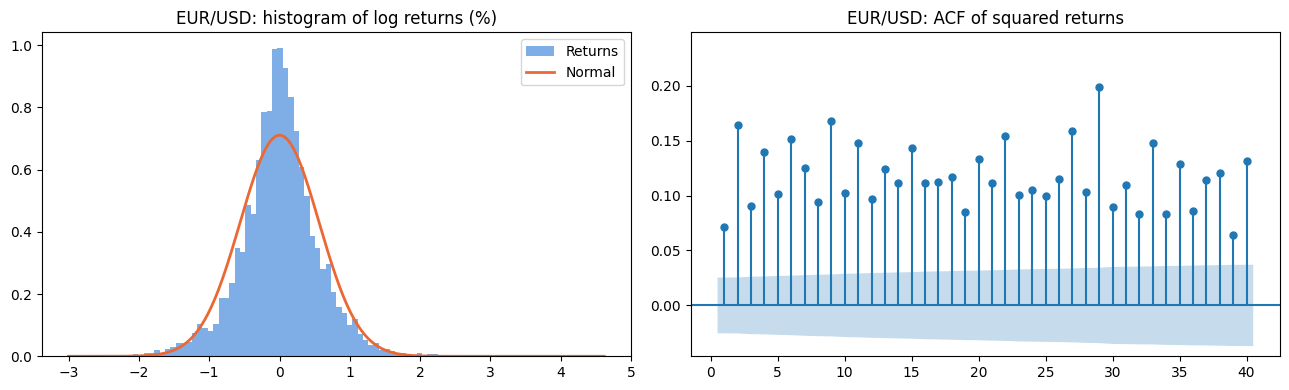

n              5978.0000
mean              0.0012
std               0.5614
ann_vol_%         8.9120
min              -3.0031
max               4.6208
skew              0.1057
excess_kurt       2.9220
JB_stat        2137.7935
JB_p              0.0000
dtype: float64

                        stat  p_value
LB returns Q(10)     14.4763   0.1524
LB squared Q(10)    934.5746   0.0000
LB returns Q(20)     22.1311   0.3334
LB squared Q(20)   1791.6528   0.0000
ARCH LM (10 lags)   492.9924   0.0000


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [ ]:
#EDA for EUR/USD first
s, t = run_eda("USEU")
print(s.round(4))
print()
print(t.round(4))

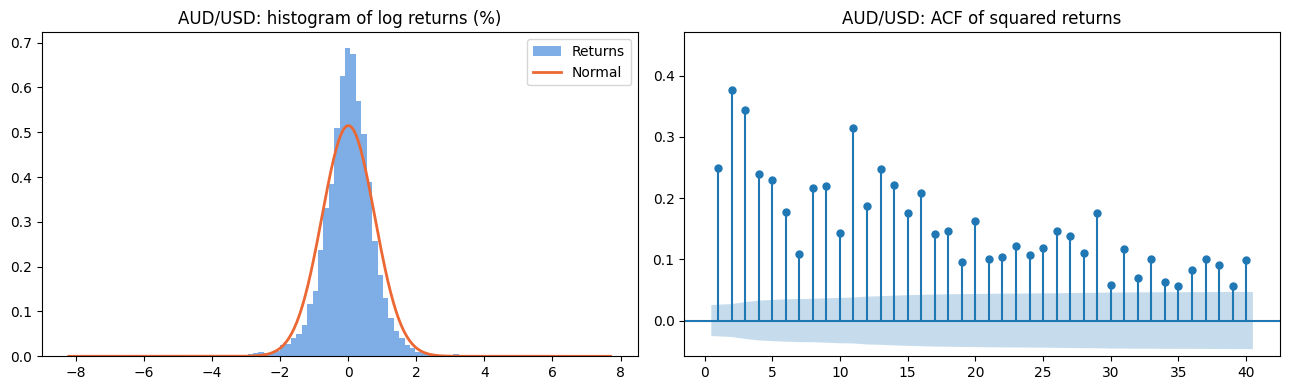

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


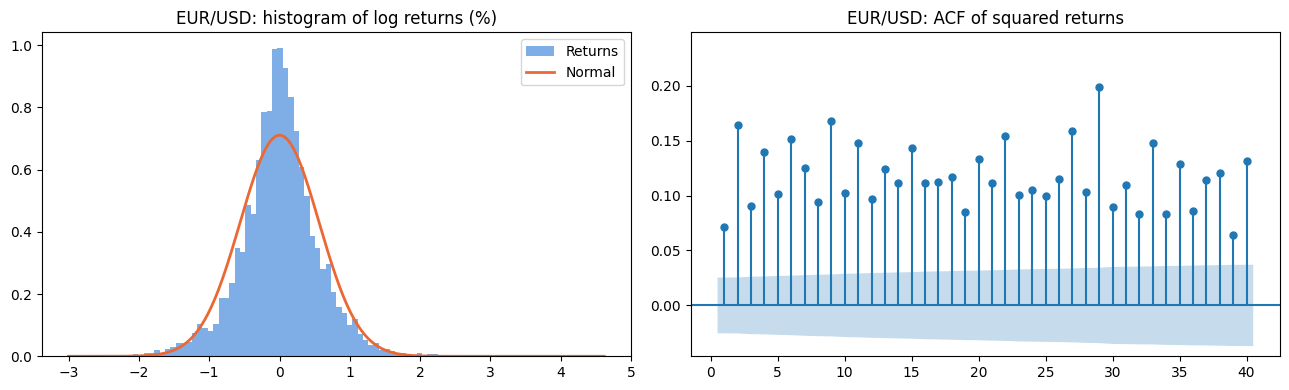

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


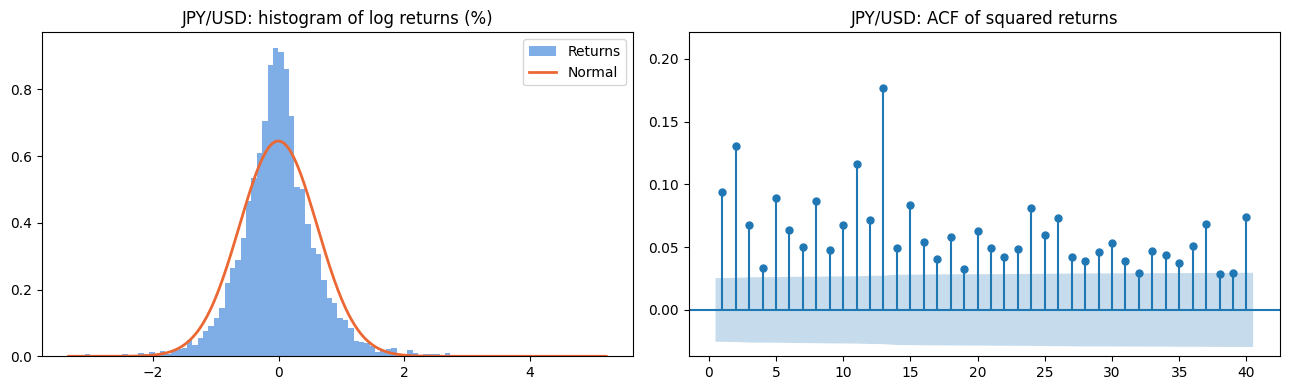

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


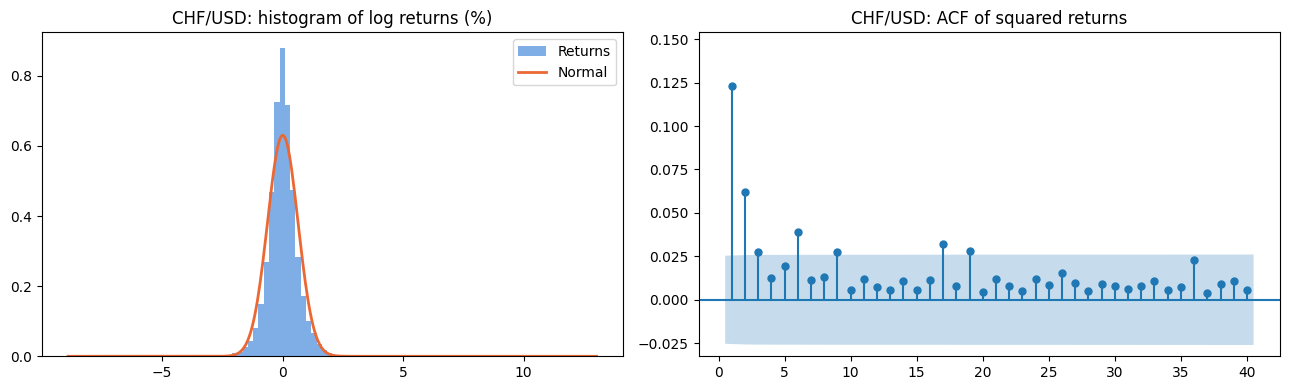

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


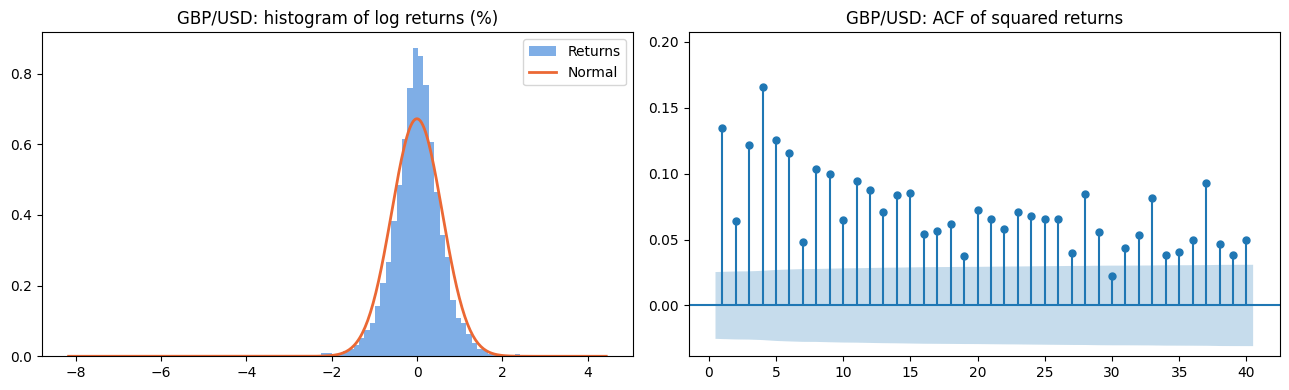

Summary stats


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,AUD/USD,EUR/USD,JPY/USD,CHF/USD,GBP/USD
n,5978.0000,5978.0000,5978.0000,5978.0000,5978.0000
mean,0.0033,0.0012,-0.0046,0.0090,-0.0030
std,0.7750,0.5614,0.6185,0.6326,0.5933
ann_vol_%,12.3030,8.9120,9.8187,10.0419,9.4190
min,-8.2120,-3.0031,-3.3428,-8.8907,-8.1694
max,7.7035,4.6208,5.2156,13.0222,4.4349
skew,-0.6128,0.1057,0.4046,1.2463,-0.6207
excess_kurt,11.9588,2.9220,4.6773,39.1914,10.2441
JB_stat,35996.3721,2137.7935,5612.2467,384130.4242,26522.8816
JB_p,0.0000,0.0000,0.0000,0.0000,0.0000


Test p-values


,AUD/USD,EUR/USD,JPY/USD,CHF/USD,GBP/USD
LB returns Q(10),0.0,0.1524,0.4265,0.0264,0.0
LB squared Q(10),0.0,0.0000,0.0000,0.0000,0.0
LB returns Q(20),0.0,0.3334,0.0913,0.0001,0.0
LB squared Q(20),0.0,0.0000,0.0000,0.0000,0.0
ARCH LM (10 lags),0.0,0.0000,0.0000,0.0000,0.0


In [ ]:
#EDA for all five pairs
all_stats, all_pvals = {}, {}
for c in CURRENCIES:
    s, t = run_eda(c)
    all_stats[PAIR_NAMES[c]] = s
    all_pvals[PAIR_NAMES[c]] = t["p_value"]

print("Summary stats")
display(pd.DataFrame(all_stats).round(4))
print("Test p-values")
display(pd.DataFrame(all_pvals).round(4))

In [ ]:
#Evaluation (MAE, RMSE, QLIKE), unit tests, empty results table
MODEL_NAMES = ["hist_30", "hist_60", "hist_250", "ewma", "garch11", "gjr_garch"]
METRICS = ["MAE", "RMSE", "QLIKE"]


def _clean(forecast, proxy):
    """Float arrays with any NaN/inf day dropped from both sides."""
    f = np.asarray(forecast, float)
    p = np.asarray(proxy, float)
    if f.shape != p.shape:
        raise ValueError(f"forecast has shape {f.shape} but proxy has shape {p.shape}")
    ok = np.isfinite(f) & np.isfinite(p)
    if not ok.any():
        raise ValueError("no valid (forecast, proxy) pairs")
    return f[ok], p[ok]


def mae(forecast, proxy):
    f, p = _clean(forecast, proxy)
    return np.mean(np.abs(p - f))


def rmse(forecast, proxy):
    f, p = _clean(forecast, proxy)
    return np.sqrt(np.mean((p - f) ** 2))


def qlike(forecast, proxy, eps=1e-12):
    # mean(log f + p / f): same model ranking as p/f - log(p/f) - 1,
    # but finite on the ~55 days per pair where the return is exactly 0
    f, p = _clean(forecast, proxy)
    f = np.maximum(f, eps)
    return np.mean(np.log(f) + p / f)


METRIC_FUNCS = {"MAE": mae, "RMSE": rmse, "QLIKE": qlike}


def empty_results_table(currencies=CURRENCIES, models=MODEL_NAMES, metrics=METRICS):
    idx = pd.MultiIndex.from_product([currencies, models], names=["currency", "model"])
    return pd.DataFrame(np.nan, index=idx, columns=metrics)


def score_currency(out, currency, results, models=MODEL_NAMES):
    """Fill one currency's rows from a walk_forward() output. Missing models stay NaN."""
    proxy = out["realized"] ** 2
    for m in models:
        if m in out.columns:
            results.loc[(currency, m), METRICS] = [METRIC_FUNCS[k](out[m], proxy) for k in METRICS]
    return results


def test_metrics():
    f = np.array([1.0, 2.0, 3.0])
    p = np.array([2.0, 2.0, 5.0])
    assert np.isclose(mae(f, p), 1.0)                           # (1 + 0 + 2) / 3
    assert np.isclose(rmse(f, p), np.sqrt(5 / 3))               # sqrt((1 + 0 + 4) / 3)
    assert np.isclose(qlike(f, p), np.mean(np.log(f) + p / f))
    assert mae(p, p) == 0 and rmse(p, p) == 0                   # perfect forecast
    assert rmse(f, p) >= mae(f, p)
    assert qlike([0.5], [1.0]) > qlike([2.0], [1.0])            # under-forecasting costs more
    rng = np.random.default_rng(1)
    prox = rng.chisquare(1, 200_000)                            # squared N(0,1) draws
    q_true = qlike(np.ones_like(prox), prox)
    assert q_true < qlike(np.full_like(prox, 1.3), prox)        # lowest at the true variance
    assert q_true < qlike(np.full_like(prox, 0.7), prox)
    assert np.isfinite(qlike([1.0, 1.0], [0.0, 1.0]))           # zero-return day is fine
    assert np.isclose(mae([1.0, np.nan, 3.0], [2.0, 5.0, 5.0]), 1.5)   # NaN day dropped
    assert np.isclose(mae(pd.Series(f), pd.Series(p)), 1.0)
    try:
        mae([1.0, 2.0], [1.0])
        raise AssertionError("expected ValueError")
    except ValueError:
        pass
    print("metric tests: PASS")


def test_results_table():
    t = empty_results_table()
    assert t.shape == (30, 3) and t.isna().all().all()
    fake = pd.DataFrame({"realized": [1.0, -2.0, 0.0],
                         "hist_30": [1.0, 4.0, 1.0], "ewma": [2.0, 2.0, 2.0]})
    score_currency(fake, "USEU", t)
    assert np.isclose(t.loc[("USEU", "hist_30"), "MAE"], 1 / 3)
    assert np.isclose(t.loc[("USEU", "ewma"), "RMSE"], np.sqrt((1 + 4 + 4) / 3))
    assert t.loc[("USEU", "garch11")].isna().all()
    assert t.loc["USAL"].isna().all().all()
    print("results table tests: PASS")


test_metrics()
test_results_table()
results = empty_results_table()
display(results)

metric tests: PASS
results table tests: PASS


MAE  RMSE  QLIKE
currency model                      
USAL     hist_30    NaN   NaN    NaN
         hist_60    NaN   NaN    NaN
         hist_250   NaN   NaN    NaN
         ewma       NaN   NaN    NaN
         garch11    NaN   NaN    NaN
         gjr_garch  NaN   NaN    NaN
USEU     hist_30    NaN   NaN    NaN
         hist_60    NaN   NaN    NaN
         hist_250   NaN   NaN    NaN
         ewma       NaN   NaN    NaN
         garch11    NaN   NaN    NaN
         gjr_garch  NaN   NaN    NaN
USJP     hist_30    NaN   NaN    NaN
         hist_60    NaN   NaN    NaN
         hist_250   NaN   NaN    NaN
         ewma       NaN   NaN    NaN
         garch11    NaN   NaN    NaN
         gjr_garch  NaN   NaN    NaN
USSZ     hist_30    NaN   NaN    NaN
         hist_60    NaN   NaN    NaN
         hist_250   NaN   NaN    NaN
         ewma       NaN   NaN    NaN
         garch11    NaN   NaN    NaN
         gjr_garch  NaN   NaN    NaN
USUK     hist_30    NaN   NaN    NaN
         hist_60    NaN   NaN    NaN
         hist_250   NaN   NaN    NaN
         ewma       NaN   NaN    NaN
         garch11    NaN   NaN    NaN
         gjr_garch  NaN   NaN    NaN

In [1]:
#Risk (VaR, ES, Kupiec, Christoffersen) on simulated data
ALPHAS = [0.01, 0.05]          # 99% and 95% VaR


def var_es(sigma2, alpha=0.01, dist="normal", nu=None, mu=0.0):
    """1-day VaR and ES (positive losses, in %) from a variance forecast."""
    sigma = np.sqrt(np.asarray(sigma2, float))
    if dist == "normal":
        z = stats.norm.ppf(alpha)
        var = -(mu + sigma * z)
        es = -mu + sigma * stats.norm.pdf(z) / alpha
    elif dist == "t":
        if nu is None or nu <= 2:
            raise ValueError("Student-t needs nu > 2")
        scale = np.sqrt((nu - 2) / nu)                          # rescale t to variance 1
        q = stats.t.ppf(alpha, nu)
        var = -(mu + sigma * scale * q)
        es = -mu + sigma * scale * (nu + q ** 2) / (nu - 1) * stats.t.pdf(q, nu) / alpha
    else:
        raise ValueError(f"unknown dist {dist!r}")
    return var, es


def var_hits(realized, var):
    """1 on days the loss beat VaR (return < -VaR), else 0."""
    return (np.asarray(realized, float) < -np.asarray(var, float)).astype(int)


def kupiec(hits, alpha):
    """Is the hit rate equal to alpha?"""
    h = np.asarray(hits, int)
    n, x = len(h), h.sum()
    pi = x / n
    ll_null = xlogy(n - x, 1 - alpha) + xlogy(x, alpha)
    ll_alt = xlogy(n - x, 1 - pi) + xlogy(x, pi)
    lr = -2 * (ll_null - ll_alt)
    return {"n": n, "hits": int(x), "hit_rate": pi, "LR_uc": lr, "p_uc": stats.chi2.sf(lr, 1)}


def christoffersen(hits, alpha):
    """Do hits cluster (independence)? Plus conditional coverage = Kupiec + independence."""
    h = np.asarray(hits, int)
    prev, curr = h[:-1], h[1:]
    n00 = np.sum((prev == 0) & (curr == 0)); n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0)); n11 = np.sum((prev == 1) & (curr == 1))
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0.0
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_null = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_alt = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
              + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))
    lr_ind = -2 * (ll_null - ll_alt)
    uc = kupiec(h, alpha)
    lr_cc = uc["LR_uc"] + lr_ind
    return {**uc, "LR_ind": lr_ind, "p_ind": stats.chi2.sf(lr_ind, 1),
            "LR_cc": lr_cc, "p_cc": stats.chi2.sf(lr_cc, 2)}


RISK_COLS = ["hits", "hit_rate", "p_uc", "p_ind", "p_cc", "avg_VaR", "avg_ES"]


def empty_risk_table(currencies=CURRENCIES, models=MODEL_NAMES, alphas=ALPHAS):
    idx = pd.MultiIndex.from_product([currencies, models, alphas],
                                     names=["currency", "model", "alpha"])
    return pd.DataFrame(np.nan, index=idx, columns=RISK_COLS)


def backtest_currency(out, currency, risk, models=MODEL_NAMES, alphas=ALPHAS,
                      dist="normal", nu=None):
    for m in models:
        if m not in out.columns:
            continue
        ok = out[m].notna() & out["realized"].notna()
        f, r = out.loc[ok, m], out.loc[ok, "realized"]
        for a in alphas:
            var, es = var_es(f, alpha=a, dist=dist, nu=nu)
            res = christoffersen(var_hits(r, var), a)
            risk.loc[(currency, m, a), RISK_COLS] = [res["hits"], res["hit_rate"], res["p_uc"],
                                                     res["p_ind"], res["p_cc"],
                                                     np.mean(var), np.mean(es)]
    return risk


def test_var_es():
    v, e = var_es(1.0, 0.01)
    assert np.isclose(v, 2.3263, atol=1e-4) and np.isclose(e, 2.6652, atol=1e-4)
    v, e = var_es(1.0, 0.05)
    assert np.isclose(v, 1.6449, atol=1e-4) and np.isclose(e, 2.0627, atol=1e-4)
    assert np.isclose(var_es(4.0, 0.01)[0], 2 * var_es(1.0, 0.01)[0])
    for d, nu in [("normal", None), ("t", 5)]:
        v1, e1 = var_es(1.0, 0.01, d, nu)
        v5, e5 = var_es(1.0, 0.05, d, nu)
        assert e1 > v1 and e5 > v5 and v1 > v5
    assert np.allclose(var_es(1.0, 0.01, "t", 1e6), var_es(1.0, 0.01), atol=1e-3)
    assert var_es(1.0, 0.01, "t", 4)[0] > var_es(1.0, 0.01)[0]
    rng = np.random.default_rng(0)
    for d, nu in [("normal", None), ("t", 6)]:
        x = rng.standard_normal(2_000_000) if d == "normal" else \
            rng.standard_t(nu, 2_000_000) * np.sqrt((nu - 2) / nu)
        v, e = var_es(1.0, 0.01, d, nu)
        q = -np.quantile(x, 0.01)
        assert np.isclose(v, q, rtol=0.01) and np.isclose(e, -x[x <= -q].mean(), rtol=0.02)
    assert list(var_hits([-3.0, -1.0, 2.0, -2.0], [2.0] * 4)) == [1, 0, 0, 0]
    print("VaR/ES tests: PASS")


def test_backtests():
    k = kupiec([1, 1] + [0] * 8, 0.1)
    expected = -2 * (8 * np.log(0.9) + 2 * np.log(0.1) - 8 * np.log(0.8) - 2 * np.log(0.2))
    assert k["hits"] == 2 and np.isclose(k["LR_uc"], expected)
    assert np.isfinite(kupiec(np.zeros(500), 0.01)["LR_uc"])
    assert np.isfinite(christoffersen(np.zeros(500), 0.01)["LR_cc"])
    assert np.isclose(kupiec([1] + [0] * 99, 0.01)["LR_uc"], 0.0)
    rng = np.random.default_rng(42)
    n = 2000
    res = christoffersen((rng.random(n) < 0.01).astype(int), 0.01)       # correct model
    assert res["p_uc"] > 0.05 and res["p_ind"] > 0.05 and res["p_cc"] > 0.05
    assert kupiec((rng.random(n) < 0.03).astype(int), 0.01)["p_uc"] < 0.01   # too many hits
    clustered = np.zeros(n, int)
    for s in rng.choice(np.arange(0, n - 5, 5), size=4, replace=False):
        clustered[s:s + 5] = 1                                           # hits in runs of 5
    assert christoffersen(clustered, 0.01)["p_ind"] < 0.01
    sigma2 = np.exp(rng.normal(0, 0.5, n)) * 0.4
    r = rng.standard_normal(n) * np.sqrt(sigma2)
    assert kupiec(var_hits(r, var_es(sigma2, 0.01)[0]), 0.01)["p_uc"] > 0.05
    assert kupiec(var_hits(r, var_es(sigma2 * 0.5, 0.01)[0]), 0.01)["p_uc"] < 0.01
    print("backtest tests: PASS")


test_var_es()
test_backtests()
risk = empty_risk_table()
print(risk.shape)

NameError: name 'CURRENCIES' is not defined

In [ ]:
#Regimes (calm/stressed rule with a no-lookahead test)
def regime_labels(returns, window=20, q=0.75, min_history=250):
    """Day t is 'stressed' if the volatility of the `window` days before t is in the
    top (1-q) of all such values seen up to t. Uses nothing from day t onward."""
    r = returns.dropna()
    rv = r.rolling(window).std().shift(1)                      # vol of days t-window .. t-1
    thr = rv.expanding(min_periods=min_history).quantile(q)    # cutoff from the past only
    lab = pd.Series(np.where(rv > thr, "stressed", "calm"), index=r.index, dtype=object)
    lab[rv.isna() | thr.isna()] = np.nan                       # warm-up days get no label
    return lab


def score_by_regime(out, regime, currency, models=MODEL_NAMES):
    """MAE/RMSE/QLIKE separately for calm and stressed days."""
    reg = regime.reindex(out.index)
    proxy = out["realized"] ** 2
    rows = []
    for g in ["calm", "stressed"]:
        mask = (reg == g).values
        for m in models:
            if m in out.columns and mask.any():
                rows.append({"currency": currency, "model": m, "regime": g, "n_days": mask.sum(),
                             **{k: METRIC_FUNCS[k](out[m][mask], proxy[mask]) for k in METRICS}})
    return pd.DataFrame(rows).set_index(["currency", "model", "regime"])


def test_regimes():
    rng = np.random.default_rng(3)
    idx = pd.bdate_range("2010-01-01", periods=1000)
    r = pd.Series(np.r_[rng.normal(0, 0.5, 700), rng.normal(0, 2.0, 300)], index=idx)
    lab = regime_labels(r)
    # stressed block is detected once the 20-day window has filled up
    assert (lab.iloc[720:820] == "stressed").mean() > 0.9
    # calm block: roughly the top quarter gets flagged, by construction
    assert 0.05 < (lab.iloc[300:700] == "stressed").mean() < 0.45

    # no lookahead 1: junk in the future leaves earlier labels alone
    k = 600
    poisoned = r.copy(); poisoned.iloc[k:] = 999.0
    pd.testing.assert_series_equal(lab.iloc[:k + 1], regime_labels(poisoned).iloc[:k + 1])
    # no lookahead 2: a shock on day j can only change labels AFTER day j
    j = 500
    shocked = r.copy(); shocked.iloc[j] = 50.0
    lab2 = regime_labels(shocked)
    pd.testing.assert_series_equal(lab.iloc[:j + 1], lab2.iloc[:j + 1])
    assert (lab2.iloc[j + 1] == "stressed") and (lab.iloc[j + 1] != lab2.iloc[j + 1])

    # real data, every pair
    for c in CURRENCIES:
        rc = get_returns(c)
        lc = regime_labels(rc)
        p = rc.copy(); p.iloc[len(rc) // 2:] = 999.0
        cut = len(rc) // 2
        pd.testing.assert_series_equal(lc.iloc[:cut + 1], regime_labels(p).iloc[:cut + 1])
    print("regime tests: PASS")


test_regimes()
regimes = {c: regime_labels(get_returns(c)) for c in CURRENCIES}
display(pd.DataFrame({PAIR_NAMES[c]: regimes[c].value_counts(normalize=True).round(3)
                      for c in CURRENCIES}))

regime tests: PASS


,AUD/USD,EUR/USD,JPY/USD,CHF/USD,GBP/USD
calm,0.804,0.813,0.744,0.861,0.78
stressed,0.196,0.187,0.256,0.139,0.22


In [ ]:
#Shared plotting helpers
MODEL_COLORS = {"hist_30": "#2a78d6", "hist_60": "#eb6834", "hist_250": "#1baf7a",
                "ewma": "#eda100", "garch11": "#e87ba4", "gjr_garch": "#008300"}
STRESS_SHADE = "#c3c2b7"


def _style(ax):
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)


def _shade_stress(ax, regime):
    s = (regime == "stressed").reindex(regime.index).fillna(False).values
    ax.fill_between(regime.index, 0, 1, where=s, transform=ax.get_xaxis_transform(),
                    color=STRESS_SHADE, alpha=0.35, lw=0, label="stressed")


def plot_regimes(returns, regime, title, show=True):
    fig, ax = plt.subplots(figsize=(13, 3.5))
    _shade_stress(ax, regime)
    ax.plot(returns.index, returns, color="#2a78d6", lw=0.6, label="daily return (%)")
    ax.set_title(title); ax.set_ylabel("log return (%)"); ax.legend(loc="upper left")
    _style(ax); fig.tight_layout()
    if show: plt.show()
    return fig


def plot_forecasts(out, title, models=None, regime=None, show=True):
    """Annualised volatility forecasts, sqrt(variance * 252), one line per model."""
    models = [m for m in (models or MODEL_NAMES) if m in out.columns]
    fig, ax = plt.subplots(figsize=(13, 4))
    if regime is not None:
        _shade_stress(ax, regime.reindex(out.index))
    for m in models:
        ax.plot(out.index, np.sqrt(out[m] * 252), color=MODEL_COLORS[m], lw=1.2, label=m)
    top = np.nanpercentile(np.sqrt(out[models] * 252), 99.5) * 1.3
    ax.set_ylim(0, top)
    ax.set_title(title); ax.set_ylabel("annualised vol (%)")
    ax.legend(loc="upper left", ncol=4, fontsize=8)
    _style(ax); fig.tight_layout()
    if show: plt.show()
    return fig


def plot_var_backtest(out, model, alpha, title, show=True):
    var, _ = var_es(out[model], alpha)
    hits = var_hits(out["realized"], var).astype(bool)
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(out.index, out["realized"], color="#c3c2b7", lw=0.5, label="daily return (%)")
    ax.plot(out.index, -var, color=MODEL_COLORS[model], lw=1.2,
            label=f"-VaR {int((1 - alpha) * 100)}% ({model})")
    ax.scatter(out.index[hits], out["realized"][hits], s=14, color="#eb6834", zorder=3,
               label=f"hits: {hits.sum()} ({hits.mean():.2%}, expected {alpha:.0%})")
    ax.set_title(title); ax.set_ylabel("%"); ax.legend(loc="lower left", fontsize=8)
    _style(ax); fig.tight_layout()
    if show: plt.show()
    return fig


def plot_metric_ranks(results, metric, show=True):
    """Rank of each model within each pair (1 = best) so pairs with different
    volatility levels can share one picture. Cell text is the metric value."""
    tab = results[metric].unstack("model")[[m for m in MODEL_NAMES
                                            if m in results.index.get_level_values("model")]]
    ranks = tab.rank(axis=1)
    fig, ax = plt.subplots(figsize=(1.6 * tab.shape[1] + 2, 0.6 * tab.shape[0] + 1.5))
    ax.imshow(ranks.values, cmap="Blues_r", vmin=1, vmax=tab.shape[1] + 2, aspect="auto")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            rk = int(ranks.iloc[i, j])
            ax.text(j, i, f"{tab.iloc[i, j]:.4f}\n#{rk}", ha="center", va="center", fontsize=8,
                    color="white" if rk <= 3 else "black")
    ax.set_xticks(range(tab.shape[1]), tab.columns)
    ax.set_yticks(range(tab.shape[0]), [PAIR_NAMES.get(c, c) for c in tab.index])
    ax.set_title(f"{metric} by pair and model (#1 = best, darker = better)")
    fig.tight_layout()
    if show: plt.show()
    return fig


def test_plots():
    rng = np.random.default_rng(5)
    idx = pd.bdate_range("2020-01-01", periods=300)
    fake = pd.DataFrame({"realized": rng.normal(0, 0.6, 300)}, index=idx)
    for m in MODEL_NAMES:
        fake[m] = 0.36 * rng.uniform(0.8, 1.2, 300)
    reg = regime_labels(pd.Series(rng.normal(0, 0.6, 600),
                                  index=pd.bdate_range("2019-01-01", periods=600)))
    res = empty_results_table(); score_currency(fake, "USEU", res); score_currency(fake, "USAL", res)
    figs = [plot_regimes(fake["realized"], reg.reindex(idx), "t", show=False),
            plot_forecasts(fake, "t", regime=reg, show=False),
            plot_var_backtest(fake, "ewma", 0.01, "t", show=False),
            plot_metric_ranks(res.dropna(), "QLIKE", show=False)]
    assert all(isinstance(f, plt.Figure) for f in figs)
    for f in figs: plt.close(f)
    print("plot helper tests: PASS")


test_plots()

plot helper tests: PASS


In [ ]:
#Plug GARCH and GJR-GARCH into the loop
class RollingGarch:
    """Walk-forward GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1).
    Re-estimates the parameters every `refit_every` days on the data before t, and on the
    days in between keeps those parameters and updates the variance with the new returns."""

    def __init__(self, o=0, refit_every=20, dist="normal"):
        self.o, self.refit_every, self.dist = o, refit_every, dist
        self.params, self.fit_len = None, None
        self.n_fits, self.n_failed = 0, 0

    def _model(self, train):
        return arch_model(train, mean="Constant", vol="GARCH", p=1, o=self.o, q=1, dist=self.dist)

    def __call__(self, train):
        n = len(train)
        if self.params is None or n < self.fit_len or n - self.fit_len >= self.refit_every:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = self._model(train).fit(disp="off")
            self.n_fits += 1
            if res.convergence_flag == 0 or self.params is None:
                self.params = res.params
            else:
                self.n_failed += 1                             # keep the last good parameters
            self.fit_len = n
        fc = self._model(train).fix(self.params).forecast(horizon=1, reindex=False)
        return float(fc.variance.iloc[-1, 0])


def test_rolling_garch():
    r = get_returns("USEU").iloc[:1500]
    for o in (0, 1):
        g = RollingGarch(o=o, refit_every=20)
        # on a refit day the forecast equals arch's own 1-day forecast
        f0 = g(r.iloc[:1000])
        res = arch_model(r.iloc[:1000], mean="Constant", vol="GARCH", p=1, o=o, q=1).fit(disp="off")
        assert np.isclose(f0, res.forecast(horizon=1, reindex=False).variance.iloc[-1, 0])
        # the next day uses the same parameters and the GARCH recursion by hand
        f1 = g(r.iloc[:1001])
        p = g.params
        e = r.iloc[1000] - p["mu"]
        by_hand = (p["omega"] + p["alpha[1]"] * e ** 2 + p.get("gamma[1]", 0) * e ** 2 * (e < 0)
                   + p["beta[1]"] * f0)
        assert np.isclose(f1, by_hand), (f1, by_hand)
        assert g.n_fits == 1
        for k in range(1002, 1041):
            g(r.iloc[:k])
        assert g.n_fits == 3                                   # refit at 1000, 1020, 1040

    # simulated GARCH data: forecasts track the true variance closely
    sim = arch_model(None, p=1, q=1)
    data = sim.simulate([0.0, 0.02, 0.08, 0.9], 1500, burn=500)
    rs = pd.Series(data["data"].values, index=pd.bdate_range("2000-01-03", periods=1500))
    g = RollingGarch(o=0, refit_every=20)
    fc = [g(rs.iloc[:i]) for i in range(500, 1500)]
    true_var = data["volatility"].values[500:] ** 2
    assert np.corrcoef(fc, true_var)[0, 1] > 0.9

    # no lookahead on a short window of real data
    check_no_lookahead(get_returns("USEU").iloc[-600:],
                       {"garch11": RollingGarch(0), "gjr_garch": RollingGarch(1)})
    print("rolling GARCH tests: PASS")


test_rolling_garch()

rolling GARCH tests: PASS


In [ ]:
#One command, all models × all pairs
def build_models(refit_every=20):
    """Fresh model objects (GARCH keeps state, so every pair gets new ones)."""
    return {"hist_30": make_hist_var(30), "hist_60": make_hist_var(60),
            "hist_250": make_hist_var(250), "ewma": make_ewma(0.94),
            "garch11": RollingGarch(o=0, refit_every=refit_every),
            "gjr_garch": RollingGarch(o=1, refit_every=refit_every)}


def next_day_vol(c, refit_every=20):
    """Each model's forecast for the trading day AFTER the last date in the file,
    as annualised volatility in %."""
    r = get_returns(c)
    return {m: np.sqrt(fn(r) * 252) for m, fn in build_models(refit_every).items()}


def run_all(currencies=CURRENCIES, refit_every=20, min_train=250):
    outs, fits = {}, {}
    results = empty_results_table(currencies)
    risk = empty_risk_table(currencies)
    by_regime = []
    for c in currencies:
        t0 = time.time()
        models = build_models(refit_every)
        out = walk_forward(get_returns(c), models, min_train=min_train)
        outs[c] = out
        fits[c] = {m: (models[m].n_fits, models[m].n_failed) for m in ["garch11", "gjr_garch"]}
        score_currency(out, c, results)
        backtest_currency(out, c, risk)
        by_regime.append(score_by_regime(out, regime_labels(get_returns(c)), c))
        print(f"{PAIR_NAMES[c]}: {len(out)} forecast days, {time.time() - t0:.0f}s, "
              f"GARCH fits (total, failed): {fits[c]}")
    latest = pd.DataFrame({PAIR_NAMES[c]: next_day_vol(c, refit_every) for c in currencies}).T
    return {"outs": outs, "results": results, "risk": risk,
            "by_regime": pd.concat(by_regime), "next_day_vol": latest, "garch_fits": fits}


run = run_all()          # <- the one command (about 1 to 3 minutes in Colab)

AUD/USD: 5728 forecast days, 85s, GARCH fits (total, failed): {'garch11': (287, 0), 'gjr_garch': (287, 0)}
EUR/USD: 5728 forecast days, 86s, GARCH fits (total, failed): {'garch11': (287, 0), 'gjr_garch': (287, 0)}
JPY/USD: 5728 forecast days, 84s, GARCH fits (total, failed): {'garch11': (287, 0), 'gjr_garch': (287, 0)}
CHF/USD: 5728 forecast days, 85s, GARCH fits (total, failed): {'garch11': (287, 0), 'gjr_garch': (287, 0)}
GBP/USD: 5728 forecast days, 83s, GARCH fits (total, failed): {'garch11': (287, 0), 'gjr_garch': (287, 0)}


In [ ]:
#Results tables
print("Forecast accuracy (lower is better)")
display(run["results"].round(4))

print("Best model per pair")
display(pd.DataFrame({k: run["results"][k].unstack("model").idxmin(axis=1) for k in METRICS})
        .rename(index=PAIR_NAMES))

print("VaR backtests (p < 0.05 = model rejected)")
display(run["risk"].round(4))

print("Accuracy in calm vs stressed periods")
display(run["by_regime"].round(4))

print("Next-day volatility forecast, annualised %")
display(run["next_day_vol"].round(2))

Forecast accuracy (lower is better)


MAE    RMSE   QLIKE
currency model                            
USAL     hist_30    0.6457  2.1480  0.2255
         hist_60    0.6542  2.2082  0.2429
         hist_250   0.6826  2.2570  0.3445
         ewma       0.6397  2.0875  0.2139
         garch11    0.6435  2.1041  0.2095
         gjr_garch  0.6405  2.0979  0.2105
USEU     hist_30    0.3291  0.6726 -0.3199
         hist_60    0.3304  0.6743 -0.3247
         hist_250   0.3420  0.6935 -0.2576
         ewma       0.3288  0.6727 -0.3279
         garch11    0.3355  0.6718 -0.3420
         gjr_garch  0.3354  0.6715 -0.3423
USJP     hist_30    0.4283  0.9905 -0.0359
         hist_60    0.4286  0.9887 -0.0414
         hist_250   0.4367  0.9963 -0.0060
         ewma       0.4238  0.9837 -0.0670
         garch11    0.4256  0.9823 -0.0832
         gjr_garch  0.4244  0.9821 -0.0830
USSZ     hist_30    0.4596  2.6516 -0.0670
         hist_60    0.4568  2.6327 -0.0482
         hist_250   0.4584  2.6228  0.0623
         ewma       0.4502  2.6308 -0.0601
         garch11    0.4676  2.6253 -0.0746
         gjr_garch  0.4516  2.6097 -0.0669
USUK     hist_30    0.3827  1.2348 -0.2031
         hist_60    0.3830  1.2306 -0.2028
         hist_250   0.3927  1.2505 -0.1155
         ewma       0.3775  1.2208 -0.2248
         garch11    0.3810  1.2239 -0.2312
         gjr_garch  0.3808  1.2260 -0.2277

Best model per pair


,MAE,RMSE,QLIKE
currency,,,
AUD/USD,ewma,ewma,garch11
EUR/USD,ewma,gjr_garch,gjr_garch
JPY/USD,ewma,gjr_garch,garch11
CHF/USD,ewma,gjr_garch,garch11
GBP/USD,ewma,ewma,garch11


VaR backtests (p < 0.05 = model rejected)


hits  hit_rate    p_uc   p_ind    p_cc  avg_VaR  \
currency model     alpha                                                     
USAL     hist_30   0.01   118.0    0.0206  0.0000  0.7086  0.0000   1.6168   
                   0.05   354.0    0.0618  0.0001  0.6742  0.0004   1.1431   
         hist_60   0.01   104.0    0.0182  0.0000  0.0522  0.0000   1.6365   
                   0.05   330.0    0.0576  0.0098  0.0380  0.0041   1.1571   
         hist_250  0.01   100.0    0.0175  0.0000  0.0381  0.0000   1.6974   
                   0.05   295.0    0.0515  0.6038  0.0034  0.0121   1.2001   
         ewma      0.01   111.0    0.0194  0.0000  0.9258  0.0000   1.6219   
                   0.05   344.0    0.0601  0.0007  0.3855  0.0022   1.1468   
         garch11   0.01    83.0    0.0145  0.0014  0.8570  0.0059   1.6752   
                   0.05   293.0    0.0512  0.6901  0.5895  0.7985   1.1844   
         gjr_garch 0.01    84.0    0.0147  0.0009  0.8366  0.0040   1.6713   
                   0.05   285.0    0.0498  0.9323  0.5409  0.8265   1.1817   
USEU     hist_30   0.01   101.0    0.0176  0.0000  0.5168  0.0000   1.2145   
                   0.05   341.0    0.0595  0.0013  0.3870  0.0039   0.8587   
         hist_60   0.01    96.0    0.0168  0.0000  0.7519  0.0000   1.2258   
                   0.05   319.0    0.0557  0.0521  0.0086  0.0048   0.8667   
         hist_250  0.01   106.0    0.0185  0.0000  0.0174  0.0000   1.2596   
                   0.05   302.0    0.0527  0.3483  0.0001  0.0002   0.8906   
         ewma      0.01   100.0    0.0175  0.0000  0.0607  0.0000   1.2182   
                   0.05   328.0    0.0573  0.0136  0.8575  0.0469   0.8614   
         garch11   0.01    75.0    0.0131  0.0247  0.1583  0.0297   1.2702   
                   0.05   277.0    0.0484  0.5667  0.1243  0.2605   0.8981   
         gjr_garch 0.01    74.0    0.0129  0.0336  0.1639  0.0397   1.2718   
                   0.05   281.0    0.0491  0.7426  0.2464  0.4840   0.8993   
USJP     hist_30   0.01    95.0    0.0166  0.0000  0.7413  0.0000   1.3525   
                   0.05   300.0    0.0524  0.4131  0.0391  0.0852   0.9563   
         hist_60   0.01    86.0    0.0150  0.0004  0.1910  0.0008   1.3705   
                   0.05   283.0    0.0494  0.8364  0.0022  0.0092   0.9691   
         hist_250  0.01    94.0    0.0164  0.0000  0.0010  0.0000   1.4010   
                   0.05   267.0    0.0466  0.2344  0.0009  0.0020   0.9906   
         ewma      0.01    89.0    0.0155  0.0001  0.7280  0.0005   1.3580   
                   0.05   285.0    0.0498  0.9323  0.1235  0.3044   0.9602   
         garch11   0.01    71.0    0.0124  0.0790  0.1818  0.0877   1.4027   
                   0.05   226.0    0.0395  0.0001  0.7111  0.0007   0.9918   
         gjr_garch 0.01    73.0    0.0127  0.0452  0.9425  0.1343   1.3965   
                   0.05   235.0    0.0410  0.0013  0.4445  0.0043   0.9874   
USSZ     hist_30   0.01    78.0    0.0136  0.0091  0.4101  0.0237   1.3260   
                   0.05   276.0    0.0482  0.5260  0.1904  0.3470   0.9375   
         hist_60   0.01    68.0    0.0119  0.1668  0.8343  0.3761   1.3488   
                   0.05   259.0    0.0452  0.0915  0.5915  0.2086   0.9537   
         hist_250  0.01    66.0    0.0115  0.2582  0.2308  0.2574   1.4017   
                   0.05   230.0    0.0402  0.0004  0.1270  0.0006   0.9911   
         ewma      0.01    79.0    0.0138  0.0064  0.9296  0.0241   1.3330   
                   0.05   265.0    0.0463  0.1891  0.0390  0.0501   0.9425   
         garch11   0.01    40.0    0.0070  0.0153  0.4532  0.0398   1.4409   
                   0.05   203.0    0.0354  0.0000  0.3708  0.0000   1.0188   
         gjr_garch 0.01    45.0    0.0079  0.0902  0.3985  0.1667   1.4142   
                   0.05   215.0    0.0375  0.0000  0.2291  0.0000   0.9999   
USUK     hist_30   0.01   113.0    0.0197  0.0000  0.0082  0.0000   1.2774   
                   0.05   347.0    0.0606  0.0004

Accuracy in calm vs stressed periods


n_days     MAE    RMSE   QLIKE
currency model     regime                                  
USAL     hist_30   calm        4592  0.3891  0.8418 -0.0048
         hist_60   calm        4592  0.4014  0.8463 -0.0041
         hist_250  calm        4592  0.4602  0.8992  0.0495
         ewma      calm        4592  0.3872  0.8392 -0.0106
         garch11   calm        4592  0.4038  0.8383 -0.0218
         gjr_garch calm        4592  0.4039  0.8376 -0.0224
         hist_30   stressed    1117  1.6997  4.5499  1.1514
         hist_60   stressed    1117  1.6921  4.6923  1.2416
         hist_250  stressed    1117  1.5962  4.7703  1.5475
         ewma      stressed    1117  1.6759  4.4055  1.1202
         garch11   stressed    1117  1.6276  4.4464  1.1474
         gjr_garch stressed    1117  1.6116  4.4321  1.1550
USEU     hist_30   calm        4642  0.2531  0.5544 -0.4873
         hist_60   calm        4642  0.2589  0.5521 -0.4939
         hist_250  calm        4642  0.2829  0.5649 -0.4436
         ewma      calm        4642  0.2527  0.5539 -0.4956
         garch11   calm        4642  0.2650  0.5517 -0.5125
         gjr_garch calm        4642  0.2653  0.5513 -0.5124
         hist_30   stressed    1067  0.6544  1.0359  0.3779
         hist_60   stressed    1067  0.6363  1.0477  0.3856
         hist_250  stressed    1067  0.5947  1.0847  0.5289
         ewma      stressed    1067  0.6552  1.0381  0.3773
         garch11   stressed    1067  0.6378  1.0400  0.3758
         gjr_garch stressed    1067  0.6358  1.0397  0.3733
USJP     hist_30   calm        4249  0.3169  0.7123 -0.2247
         hist_60   calm        4249  0.3325  0.7151 -0.2324
         hist_250  calm        4249  0.3633  0.7221 -0.2192
         ewma      calm        4249  0.3137  0.7096 -0.2612
         garch11   calm        4249  0.3322  0.7089 -0.2858
         gjr_garch calm        4249  0.3314  0.7093 -0.2818
         hist_30   stressed    1460  0.7559  1.5401  0.5243
         hist_60   stressed    1460  0.7106  1.5316  0.5236
         hist_250  stressed    1460  0.6528  1.5414  0.6239
         ewma      stressed    1460  0.7476  1.5266  0.5088
         garch11   stressed    1460  0.6999  1.5239  0.5153
         gjr_garch stressed    1460  0.6976  1.5229  0.5047
USSZ     hist_30   calm        4915  0.3406  2.4974 -0.2076
         hist_60   calm        4915  0.3510  2.4938 -0.1931
         hist_250  calm        4915  0.3788  2.4885 -0.0921
         ewma      calm        4915  0.3337  2.4833 -0.1963
         garch11   calm        4915  0.3607  2.4837 -0.2174
         gjr_garch calm        4915  0.3540  2.4817 -0.2060
         hist_30   stressed     794  1.1912  3.4768  0.7761
         hist_60   stressed     794  1.1066  3.3885  0.8277
         hist_250  stressed     794  0.9462  3.3569  0.9990
         ewma      stressed     794  1.1661  3.4251  0.7601
         garch11   stressed     794  1.1249  3.3931  0.7872
         gjr_garch stressed     794  1.0510  3.3143  0.7724
USUK     hist_30   calm        4451  0.2465  0.4495 -0.4201
         hist_60   calm        4451  0.2549  0.4566 -0.4395
         hist_250  calm        4451  0.2824  0.4678 -0.3916
         ewma      calm        4451  0.2455  0.4478 -0.4355
         garch11   calm        4451  0.2549  0.4472 -0.4487
         gjr_garch calm        4451  0.2548  0.4470 -0.4498
         hist_30   stressed    1258  0.8626  2.4939  0.5349
         hist_60   stressed    1258  0.8343  2.4798  0.6055
         hist_250  stressed    1258  0.7811  2.5176  0.8423
         ewma      stressed    1258  0.8420  2.4635  0.5002
         garch11   stressed    1258  0.8253  2.4709  0.5193
         gjr_garch stressed    1258  0.8243  2.4757  0.5384

Next-day volatility forecast, annualised %


,hist_30,hist_60,hist_250,ewma,garch11,gjr_garch
AUD/USD,7.20,6.45,7.63,7.94,8.55,8.84
EUR/USD,5.93,5.05,5.49,5.37,5.77,5.90
JPY/USD,5.23,7.46,7.95,5.84,7.01,7.08
CHF/USD,6.41,6.53,7.44,6.49,7.28,7.05
GBP/USD,6.12,5.28,6.21,5.95,6.62,6.65


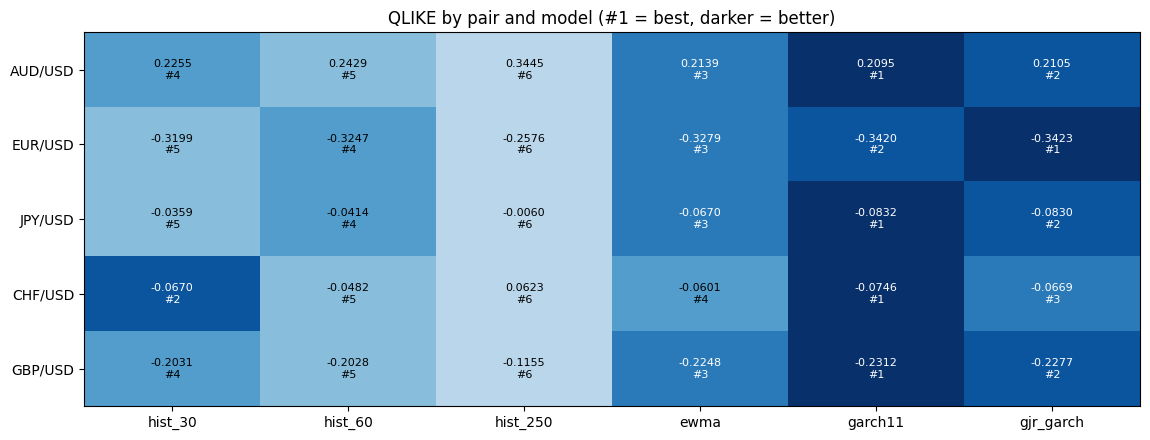

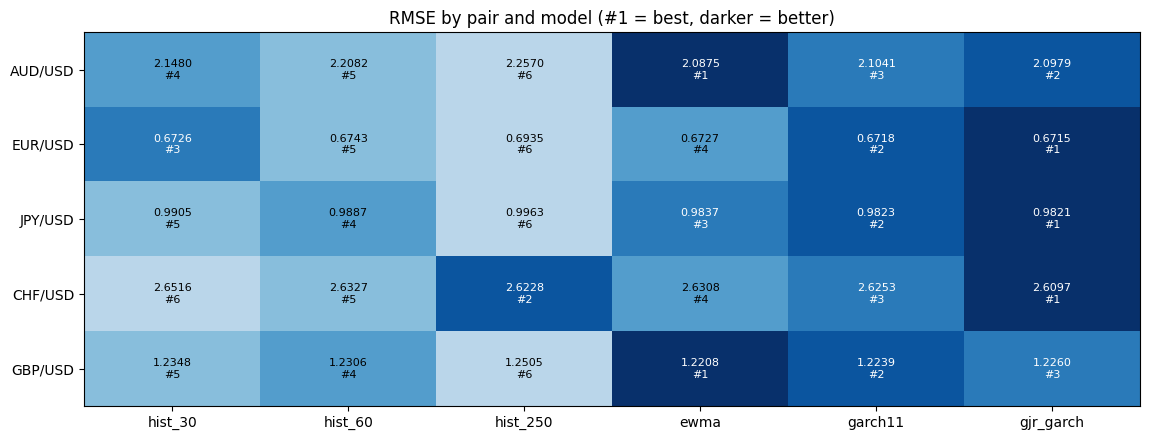

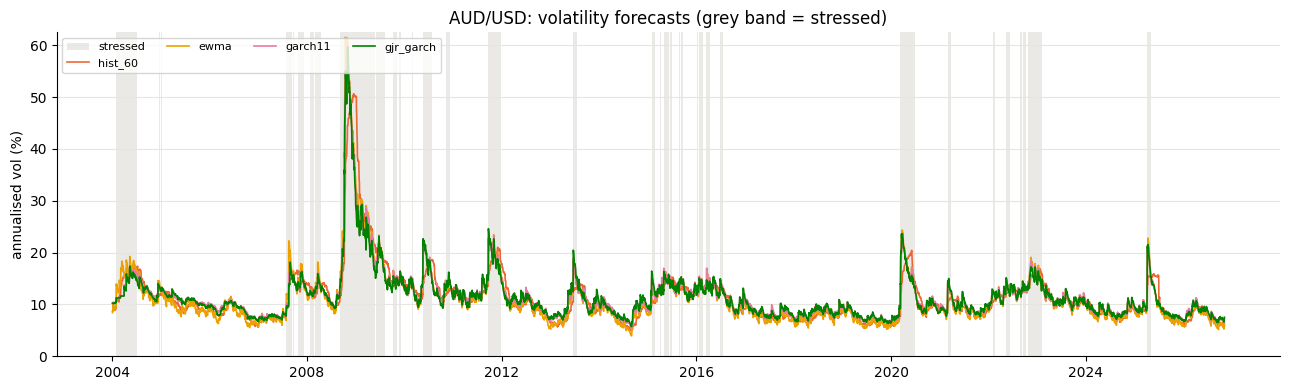

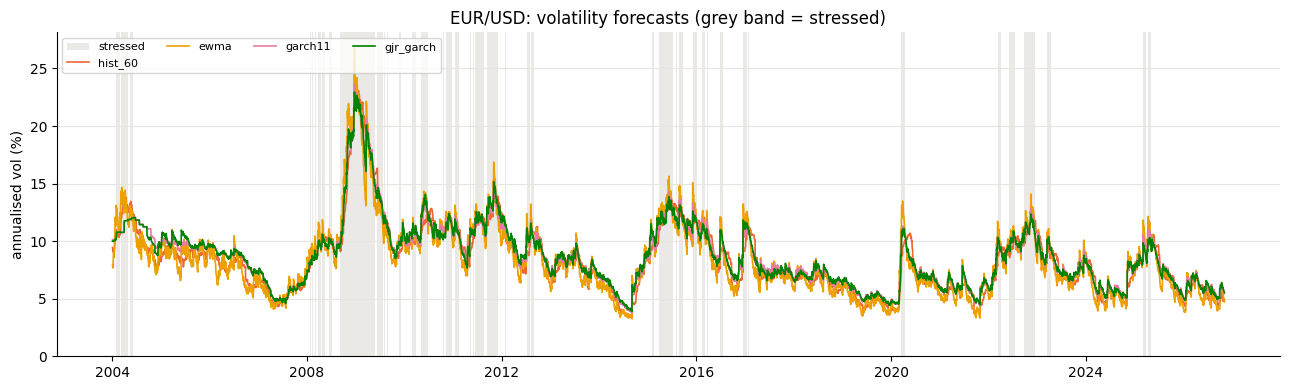

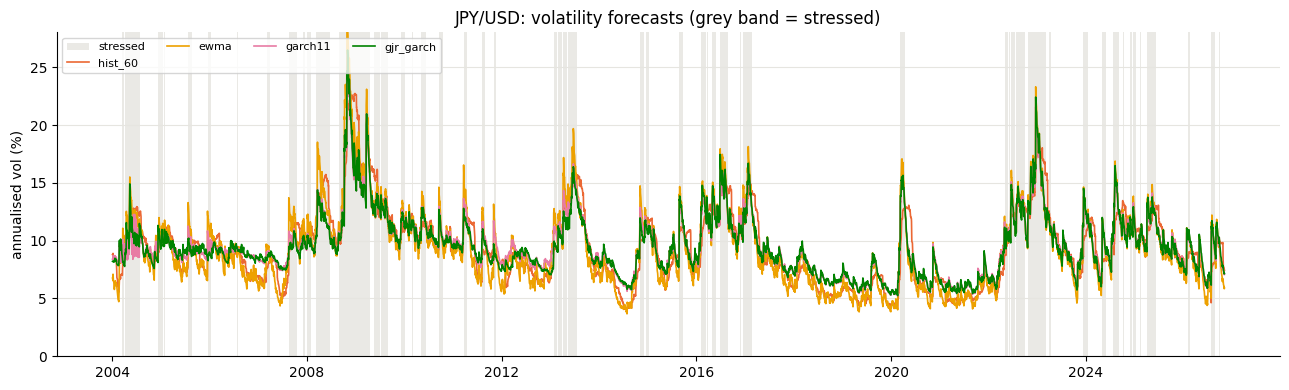

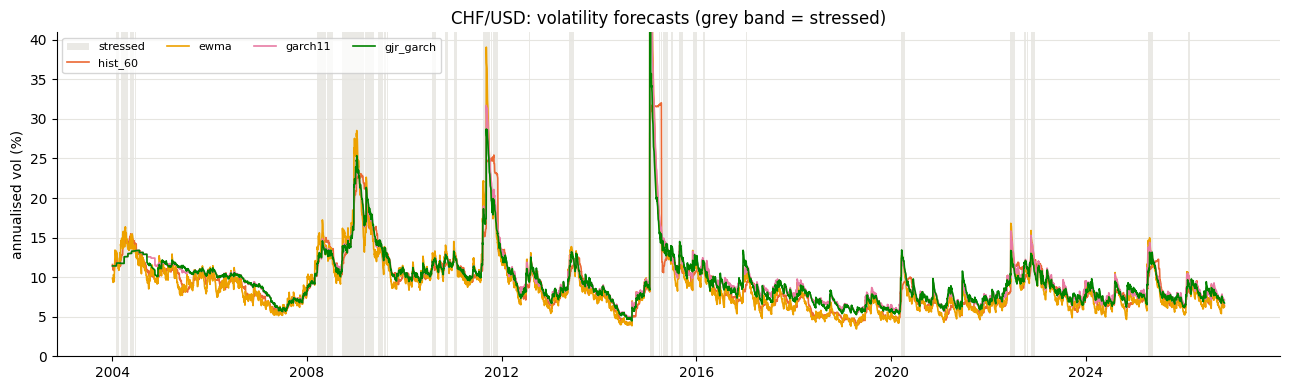

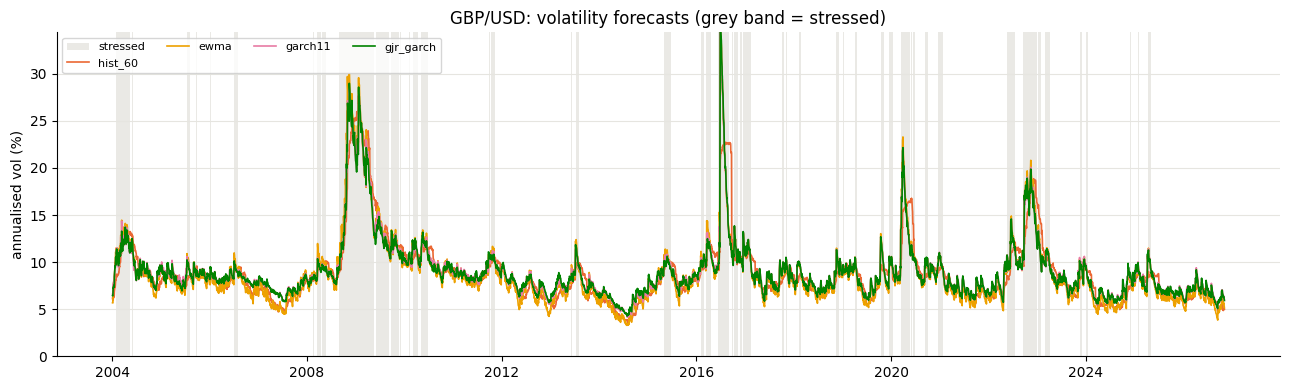

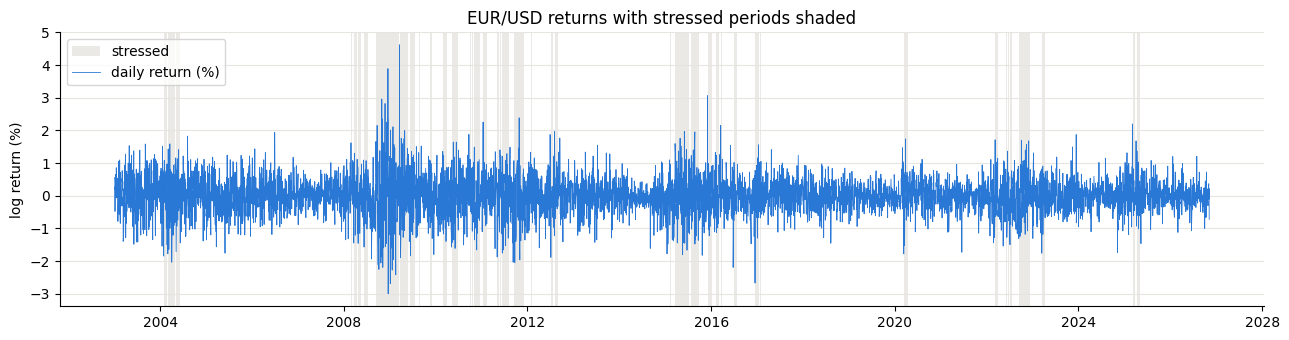

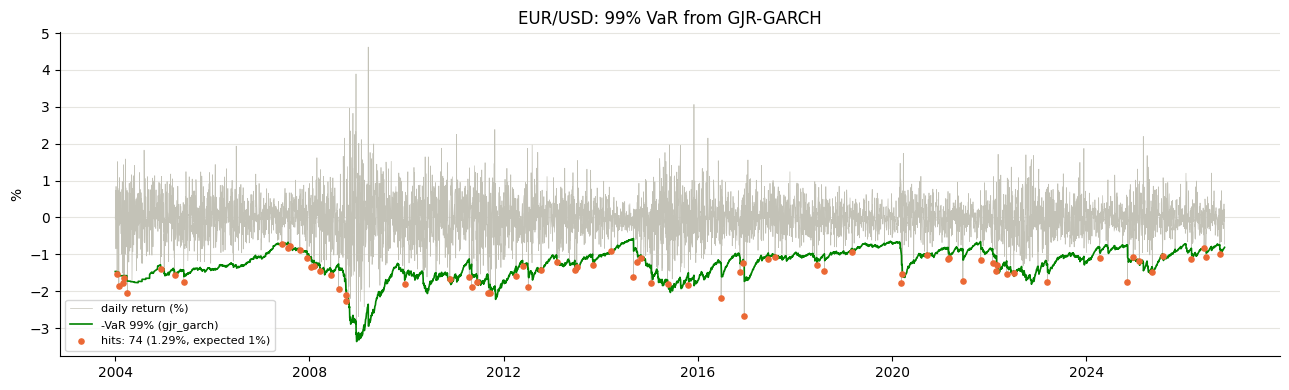

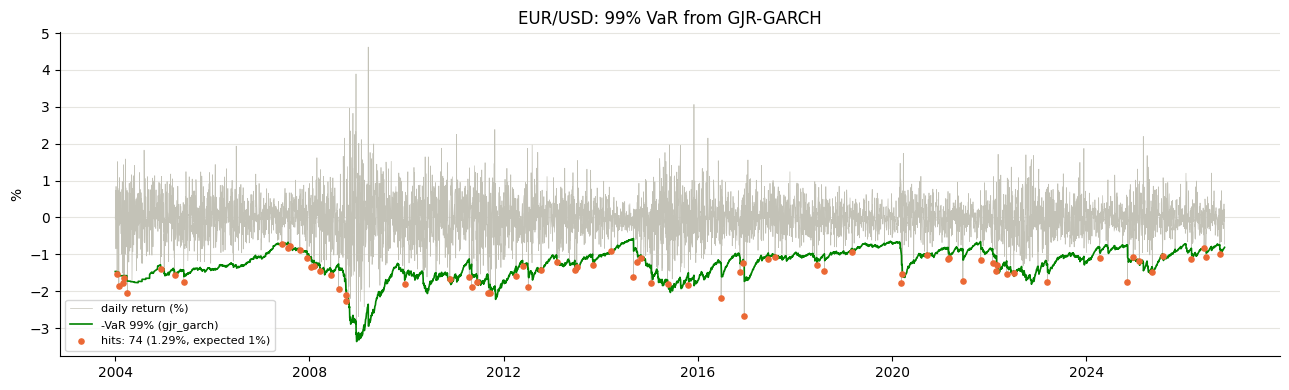

In [ ]:
#Plots
plot_metric_ranks(run["results"], "QLIKE")
plot_metric_ranks(run["results"], "RMSE")

for c in CURRENCIES:
    plot_forecasts(run["outs"][c], f"{PAIR_NAMES[c]}: volatility forecasts (grey band = stressed)",
                   models=["hist_60", "ewma", "garch11", "gjr_garch"], regime=regimes[c])

plot_regimes(get_returns("USEU"), regimes["USEU"], "EUR/USD returns with stressed periods shaded")
plot_var_backtest(run["outs"]["USEU"], "gjr_garch", 0.01, "EUR/USD: 99% VaR from GJR-GARCH")

In [ ]:
#Check and close
def final_checks(run):
    outs = run["outs"]
    # every pair produced a forecast for every model on every day, all positive
    for c, out in outs.items():
        assert list(out.columns) == ["realized"] + MODEL_NAMES, c
        f = out[MODEL_NAMES]
        assert np.isfinite(f.values).all() and (f.values > 0).all(), c
        # forecasts are on the right scale: average forecast vs average squared return
        ratio = f.mean() / (out["realized"] ** 2).mean()
        assert ratio.between(0.5, 2.0).all(), (c, ratio.round(2).to_dict())
        assert out.index.equals(get_returns(c).index[250:]), c
    # every results/risk cell is filled
    assert run["results"].notna().all().all()
    assert run["risk"].notna().all().all()
    assert run["next_day_vol"].notna().all().all()
    # the loop forecast for the last day matches calling the model directly (no hidden state bugs)
    for c in CURRENCIES:
        r = get_returns(c)
        direct = {m: fn(r.iloc[:-1]) for m, fn in build_models().items()
                  if m in ["hist_30", "hist_60", "hist_250", "ewma"]}
        for m, v in direct.items():
            assert np.isclose(outs[c][m].iloc[-1], v), (c, m)
    print("final checks: PASS")


final_checks(run)

final checks: PASS
